<a href="https://colab.research.google.com/github/RanjaniRajendran28/SivaranjaniModule---2-Module-End-Assignment-23-11-2026/blob/main/Module_2_Module_End_Assignment.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Problem Statement
In this project, you will analyze an online retail dataset containing customer transactions, product
details, quantities, prices, and purchase dates.
Businesses use such data to understand sales trends, customer behavior, and product performance.
However, raw data requires cleaning, transformation, and analysis to generate meaningful insights.
You will build a data analysis pipeline using NumPy, Pandas, Matplotlib, and Seaborn to clean data,
perform analysis, visualize patterns, and derive actionable business insights.

Objective
● Clean and preprocess real-world data
● Perform exploratory data analysis (EDA)
● Create new features for analysis
● Visualize trends using charts
● Generate business insights

Dataset: Online Retail Dataset – UCI Repository
Assignment Tasks:
Task 1 – Data Import & Setup
● Load dataset using Pandas
● Explore structure: head(), tail(), shape, columns
● Convert InvoiceDate to datetime

In [ ]:
#. Import the required libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Set display options
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', 100)

# Set visualization style
sns.set_style('whitegrid')

In [6]:
#2. Load the dataset
#Download the dataset from the UCI repository:

# Load the dataset
df = pd.read_excel('Online Retail.xlsx')

# Display first five records
df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [5]:
from google.colab import files

uploaded = files.upload()

Saving Online Retail.xlsx to Online Retail.xlsx


In [7]:
#3. Explore the dataset structure
#A. Display the first five rows

df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [8]:
#B. Display the last five rows
df.tail()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
541904,581587,22613,PACK OF 20 SPACEBOY NAPKINS,12,2011-12-09 12:50:00,0.85,12680.0,France
541905,581587,22899,CHILDREN'S APRON DOLLY GIRL,6,2011-12-09 12:50:00,2.10,12680.0,France
541906,581587,23254,CHILDRENS CUTLERY DOLLY GIRL,4,2011-12-09 12:50:00,4.15,12680.0,France
541907,581587,23255,CHILDRENS CUTLERY CIRCUS PARADE,4,2011-12-09 12:50:00,4.15,12680.0,France
541908,581587,22138,BAKING SET 9 PIECE RETROSPOT,3,2011-12-09 12:50:00,4.95,12680.0,France


In [9]:
#C. Check the number of rows and columns
df.shape

(541909, 8)

In [10]:
#D. Display all column names
df.columns

Index(['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate',
       'UnitPrice', 'CustomerID', 'Country'],
      dtype='object')

In [11]:
#df.columns
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[ns]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  object        
dtypes: datetime64[ns](1), float64(2), int64(1), object(4)
memory usage: 33.1+ MB


In [12]:
#4. Convert InvoiceDate into datetime format

# Convert InvoiceDate to datetime
df['InvoiceDate'] = pd.to_datetime(df['InvoiceDate'])

# Check the datatype
df['InvoiceDate'].dtype

dtype('<M8[ns]')

In [13]:
#5. Verify the conversion
# Display first five invoice dates
df['InvoiceDate'].head()

,InvoiceDate
0,2010-12-01 08:26:00
1,2010-12-01 08:26:00
2,2010-12-01 08:26:00
3,2010-12-01 08:26:00
4,2010-12-01 08:26:00


Task 2 – Data Cleaning
● Handle missing values (remove null CustomerID)
● Remove duplicates
● Fix invalid values (negative quantity, invalid price)

In [14]:
#1. Check missing values

# Check missing values
df.isnull().sum()

,0
InvoiceNo,0
StockCode,0
Description,1454
Quantity,0
InvoiceDate,0
UnitPrice,0
CustomerID,135080
Country,0


In [15]:
# Missing value percentage
(df.isnull().sum() / len(df)) * 100

,0
InvoiceNo,0.000000
StockCode,0.000000
Description,0.268311
Quantity,0.000000
InvoiceDate,0.000000
UnitPrice,0.000000
CustomerID,24.926694
Country,0.000000


In [16]:
# Remove rows with missing CustomerID
df = df.dropna(subset=['CustomerID'])

# Check missing values again
df.isnull().sum()

,0
InvoiceNo,0
StockCode,0
Description,0
Quantity,0
InvoiceDate,0
UnitPrice,0
CustomerID,0
Country,0


In [17]:
df = df.dropna(subset=['Description'])

In [18]:
# Count duplicate records
df.duplicated().sum()

np.int64(5225)

In [19]:
# Remove duplicate records
df = df.drop_duplicates()

# Verify duplicates are removed
df.duplicated().sum()

np.int64(0)

In [20]:
# 4. Fix invalid values

# Count negative quantities
(df['Quantity'] < 0).sum()

np.int64(8872)

In [22]:
# Keep only positive quantities
df = df[df['Quantity'] > 0]

In [23]:
#B. Remove invalid prices

# Count zero or negative prices
(df['UnitPrice'] <= 0).sum()


np.int64(40)

In [24]:
# Keep only positive unit prices
df = df[df['UnitPrice'] > 0]

In [25]:
#5. Verify the cleaned dataset

# Check dataset information
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 392692 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    392692 non-null  object        
 1   StockCode    392692 non-null  object        
 2   Description  392692 non-null  object        
 3   Quantity     392692 non-null  int64         
 4   InvoiceDate  392692 non-null  datetime64[ns]
 5   UnitPrice    392692 non-null  float64       
 6   CustomerID   392692 non-null  float64       
 7   Country      392692 non-null  object        
dtypes: datetime64[ns](1), float64(2), int64(1), object(4)
memory usage: 27.0+ MB


In [26]:
df.isnull().sum()

,0
InvoiceNo,0
StockCode,0
Description,0
Quantity,0
InvoiceDate,0
UnitPrice,0
CustomerID,0
Country,0


In [27]:
df.duplicated().sum()

np.int64(0)

In [28]:
(df['Quantity'] <= 0).sum()

np.int64(0)

Task 3 – Feature Engineering
● Create TotalPrice = Quantity × UnitPrice
● Extract time features (Year, Month, Day, Hour)
● Create categories (Customer Segment, Order Size, Day Type)

In [29]:
# 1. Create TotalPrice column
# Create TotalPrice column
df['TotalPrice'] = df['Quantity'] * df['UnitPrice']

# Display first five rows
df[['Quantity', 'UnitPrice', 'TotalPrice']].head()

,Quantity,UnitPrice,TotalPrice
0,6,2.55,15.30
1,6,3.39,20.34
2,8,2.75,22.00
3,6,3.39,20.34
4,6,3.39,20.34


In [30]:
#2. Extract time features
# Extract year
df['Year'] = df['InvoiceDate'].dt.year

# Extract month
df['Month'] = df['InvoiceDate'].dt.month

# Extract day
df['Day'] = df['InvoiceDate'].dt.day

# Extract hour
df['Hour'] = df['InvoiceDate'].dt.hour

# Display results
df[['InvoiceDate', 'Year', 'Month', 'Day', 'Hour']].head()

,InvoiceDate,Year,Month,Day,Hour
0,2010-12-01 08:26:00,2010,12,1,8
1,2010-12-01 08:26:00,2010,12,1,8
2,2010-12-01 08:26:00,2010,12,1,8
3,2010-12-01 08:26:00,2010,12,1,8
4,2010-12-01 08:26:00,2010,12,1,8


3. Create Customer Segment
We will categorize customers based on their total spending.

First, calculate the total spending of each customer.

In [31]:
# Calculate total spending per customer
customer_spending = df.groupby('CustomerID')['TotalPrice'].sum()

# Display customer spending
customer_spending.head()

,TotalPrice
CustomerID,
12346.0,77183.60
12347.0,4310.00
12348.0,1797.24
12349.0,1757.55
12350.0,334.40


Now categorize customers into three segments:

Low Value: Spending below £500.

Medium Value: Spending between £500 and £2,000.

High Value: Spending above £2,000

In [32]:
# Create customer segments
def customer_segment(amount):
    if amount < 500:
        return 'Low Value'
    elif amount <= 2000:
        return 'Medium Value'
    else:
        return 'High Value'

# Create Customer Segment column
df['Customer Segment'] = df['CustomerID'].map(
    customer_spending.apply(customer_segment)
)

# Display results
df[['CustomerID', 'TotalPrice', 'Customer Segment']].head()

,CustomerID,TotalPrice,Customer Segment
0,17850.0,15.30,High Value
1,17850.0,20.34,High Value
2,17850.0,22.00,High Value
3,17850.0,20.34,High Value
4,17850.0,20.34,High Value


4. Create Order Size category
We will classify orders based on the quantity purchased.

Categories:

Small Order: Quantity between 1 and 5.

Medium Order: Quantity between 6 and 20.

Large Order: Quantity greater than 20.



In [33]:
# Create order size categories
def order_size(quantity):
    if quantity <= 5:
        return 'Small Order'
    elif quantity <= 20:
        return 'Medium Order'
    else:
        return 'Large Order'

# Create Order Size column
df['Order Size'] = df['Quantity'].apply(order_size)

# Display results
df[['Quantity', 'Order Size']].head(10)

,Quantity,Order Size
0,6,Medium Order
1,6,Medium Order
2,8,Medium Order
3,6,Medium Order
4,6,Medium Order
5,2,Small Order
6,6,Medium Order
7,6,Medium Order
8,6,Medium Order
9,32,Large Order


5. Create Day Type category
We will classify purchase dates into weekdays and weekends.

Weekday: Monday to Friday.

Weekend: Saturday and Sunday.

In [34]:
# Extract day of week
df['DayOfWeek'] = df['InvoiceDate'].dt.dayofweek

# Create Day Type column
df['Day Type'] = df['DayOfWeek'].apply(
    lambda x: 'Weekend' if x >= 5 else 'Weekday'
)

# Display results
df[['InvoiceDate', 'DayOfWeek', 'Day Type']].head(10)

,InvoiceDate,DayOfWeek,Day Type
0,2010-12-01 08:26:00,2,Weekday
1,2010-12-01 08:26:00,2,Weekday
2,2010-12-01 08:26:00,2,Weekday
3,2010-12-01 08:26:00,2,Weekday
4,2010-12-01 08:26:00,2,Weekday
5,2010-12-01 08:26:00,2,Weekday
6,2010-12-01 08:26:00,2,Weekday
7,2010-12-01 08:28:00,2,Weekday
8,2010-12-01 08:28:00,2,Weekday
9,2010-12-01 08:34:00,2,Weekday


In [35]:
#7. Verify the newly created columns
# Display all columns
print(df.columns)

# Display newly created features
df[[
    'TotalPrice',
    'Year',
    'Month',
    'Day',
    'Hour',
    'Customer Segment',
    'Order Size',
    'Day Type'
]].head(10)

Index(['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate',
       'UnitPrice', 'CustomerID', 'Country', 'TotalPrice', 'Year', 'Month',
       'Day', 'Hour', 'Customer Segment', 'Order Size', 'DayOfWeek',
       'Day Type'],
      dtype='object')


,TotalPrice,Year,Month,Day,Hour,Customer Segment,Order Size,Day Type
0,15.30,2010,12,1,8,High Value,Medium Order,Weekday
1,20.34,2010,12,1,8,High Value,Medium Order,Weekday
2,22.00,2010,12,1,8,High Value,Medium Order,Weekday
3,20.34,2010,12,1,8,High Value,Medium Order,Weekday
4,20.34,2010,12,1,8,High Value,Medium Order,Weekday
5,15.30,2010,12,1,8,High Value,Small Order,Weekday
6,25.50,2010,12,1,8,High Value,Medium Order,Weekday
7,11.10,2010,12,1,8,High Value,Medium Order,Weekday
8,11.10,2010,12,1,8,High Value,Medium Order,Weekday
9,54.08,2010,12,1,8,High Value,Large Order,Weekday


Task 4 – Data Exploration
● Use describe() and dataset overview
● Analyze categories (value_counts(), unique())
● Perform groupby() (country, month, product)

In [36]:
# 1. Dataset overview
print("Dataset Shape:", df.shape)
print("\nDataset Information:")
df.info()

# 2. Statistical summary
print("\nStatistical Summary:")
print(df.describe())

# 3. Category analysis
print("\nTop 10 Countries:")
print(df['Country'].value_counts().head(10))

print("\nTop 10 Products:")
print(df['Description'].value_counts().head(10))

print("\nCustomer Segments:")
print(df['Customer Segment'].value_counts())

print("\nOrder Sizes:")
print(df['Order Size'].value_counts())

# 4. Unique values
print("\nUnique Countries:", df['Country'].nunique())
print("Unique Products:", df['Description'].nunique())
print("Unique Customers:", df['CustomerID'].nunique())

# 5. GroupBy analysis
print("\nCountry-wise Revenue:")
print(df.groupby('Country')['TotalPrice'].sum().sort_values(ascending=False).head(10))

print("\nMonthly Revenue:")
print(df.groupby('Month')['TotalPrice'].sum())

print("\nTop 10 Products by Revenue:")
print(df.groupby('Description')['TotalPrice'].sum().sort_values(ascending=False).head(10))

print("\nTop 10 Customers:")
print(df.groupby('CustomerID')['TotalPrice'].sum().sort_values(ascending=False).head(10))

Dataset Shape: (392692, 17)

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
Index: 392692 entries, 0 to 541908
Data columns (total 17 columns):
 #   Column            Non-Null Count   Dtype         
---  ------            --------------   -----         
 0   InvoiceNo         392692 non-null  object        
 1   StockCode         392692 non-null  object        
 2   Description       392692 non-null  object        
 3   Quantity          392692 non-null  int64         
 4   InvoiceDate       392692 non-null  datetime64[ns]
 5   UnitPrice         392692 non-null  float64       
 6   CustomerID        392692 non-null  float64       
 7   Country           392692 non-null  object        
 8   TotalPrice        392692 non-null  float64       
 9   Year              392692 non-null  int32         
 10  Month             392692 non-null  int32         
 11  Day               392692 non-null  int32         
 12  Hour              392692 non-null  int32         
 13  Customer Segme

Task 5 – Data Wrangling
● Aggregate data using groupby()
● Sort to find the top customers and countries
● Restructure data if needed

In [37]:
# 1. Country-wise aggregation
country_analysis = df.groupby('Country').agg({
    'TotalPrice': 'sum',
    'Quantity': 'sum',
    'InvoiceNo': 'nunique'
}).reset_index()

country_analysis.columns = [
    'Country',
    'Total Revenue',
    'Total Quantity',
    'Total Orders'
]

# 2. Customer-wise aggregation
customer_analysis = df.groupby('CustomerID').agg({
    'TotalPrice': 'sum',
    'InvoiceNo': 'nunique',
    'Quantity': 'sum'
}).reset_index()

customer_analysis.columns = [
    'CustomerID',
    'Total Spending',
    'Total Orders',
    'Total Quantity'
]

# 3. Product-wise aggregation
product_analysis = df.groupby('Description').agg({
    'TotalPrice': 'sum',
    'Quantity': 'sum'
}).reset_index()

# 4. Monthly aggregation
monthly_analysis = df.groupby(
    ['Year', 'Month']
).agg({
    'TotalPrice': 'sum',
    'Quantity': 'sum'
}).reset_index()

# 5. Top 10 customers
top_customers = customer_analysis.sort_values(
    by='Total Spending',
    ascending=False
).head(10)

# 6. Top 10 countries
top_countries = country_analysis.sort_values(
    by='Total Revenue',
    ascending=False
).head(10)

# 7. Top 10 products
top_products = product_analysis.sort_values(
    by='TotalPrice',
    ascending=False
).head(10)

# 8. Pivot table
monthly_pivot = pd.pivot_table(
    df,
    values='TotalPrice',
    index='Year',
    columns='Month',
    aggfunc='sum',
    fill_value=0
)

# Display results
print("TOP 10 CUSTOMERS")
print(top_customers)

print("\nTOP 10 COUNTRIES")
print(top_countries)

print("\nTOP 10 PRODUCTS")
print(top_products)

print("\nMONTHLY SALES ANALYSIS")
print(monthly_analysis)

print("\nMONTHLY PIVOT TABLE")
print(monthly_pivot)

TOP 10 CUSTOMERS
      CustomerID  Total Spending  Total Orders  Total Quantity
1689     14646.0       280206.02            73          196915
4201     18102.0       259657.30            60           64124
3728     17450.0       194390.79            46           69973
3008     16446.0       168472.50             2           80997
1879     14911.0       143711.17           201           80240
55       12415.0       124914.53            21           77374
1333     14156.0       117210.08            55           57768
3771     17511.0        91062.38            31           64549
2702     16029.0        80850.84            63           40108
0        12346.0        77183.60             1           74215

TOP 10 COUNTRIES
           Country  Total Revenue  Total Quantity  Total Orders
35  United Kingdom    7285024.644         4241305         16646
23     Netherlands     285446.340          200361            94
10            EIRE     265262.460          140133           260
14         Germa

Task 6 – Statistical Analysis
● Analyze Quantity, UnitPrice, TotalPrice
● Calculate mean, median, and mode
● Find standard deviation, variance, and percentiles

In [38]:
# Select numerical columns
numerical_data = df[['Quantity', 'UnitPrice', 'TotalPrice']]

# Mean
print("MEAN")
print(numerical_data.mean())

# Median
print("\nMEDIAN")
print(numerical_data.median())

# Mode
print("\nMODE")
print(numerical_data.mode().iloc[0])

# Standard Deviation
print("\nSTANDARD DEVIATION")
print(numerical_data.std())

# Variance
print("\nVARIANCE")
print(numerical_data.var())

# Percentiles
print("\nPERCENTILES")
print(numerical_data.quantile([0.25, 0.50, 0.75, 0.90, 0.95]))

# Complete statistical summary
print("\nCOMPLETE STATISTICAL SUMMARY")
print(numerical_data.describe())

MEAN
Quantity      13.119702
UnitPrice      3.125914
TotalPrice    22.631500
dtype: float64

MEDIAN
Quantity       6.00
UnitPrice      1.95
TotalPrice    12.45
dtype: float64

MODE
Quantity       1.00
UnitPrice      1.25
TotalPrice    15.00
Name: 0, dtype: float64

STANDARD DEVIATION
Quantity      180.492832
UnitPrice      22.241836
TotalPrice    311.099224
dtype: float64

VARIANCE
Quantity      32577.662399
UnitPrice       494.699251
TotalPrice    96782.727382
dtype: float64

PERCENTILES
      Quantity  UnitPrice  TotalPrice
0.25       2.0       1.25        4.95
0.50       6.0       1.95       12.45
0.75      12.0       3.75       19.80
0.90      24.0       6.35       35.40
0.95      36.0       8.50       67.50

COMPLETE STATISTICAL SUMMARY
            Quantity      UnitPrice     TotalPrice
count  392692.000000  392692.000000  392692.000000
mean       13.119702       3.125914      22.631500
std       180.492832      22.241836     311.099224
min         1.000000       0.001000       0.

Task 7 – Data Visualization (Min 8 Plots)
Matplotlib:
● Line chart
● Bar chart
● Histogram
● Box plot

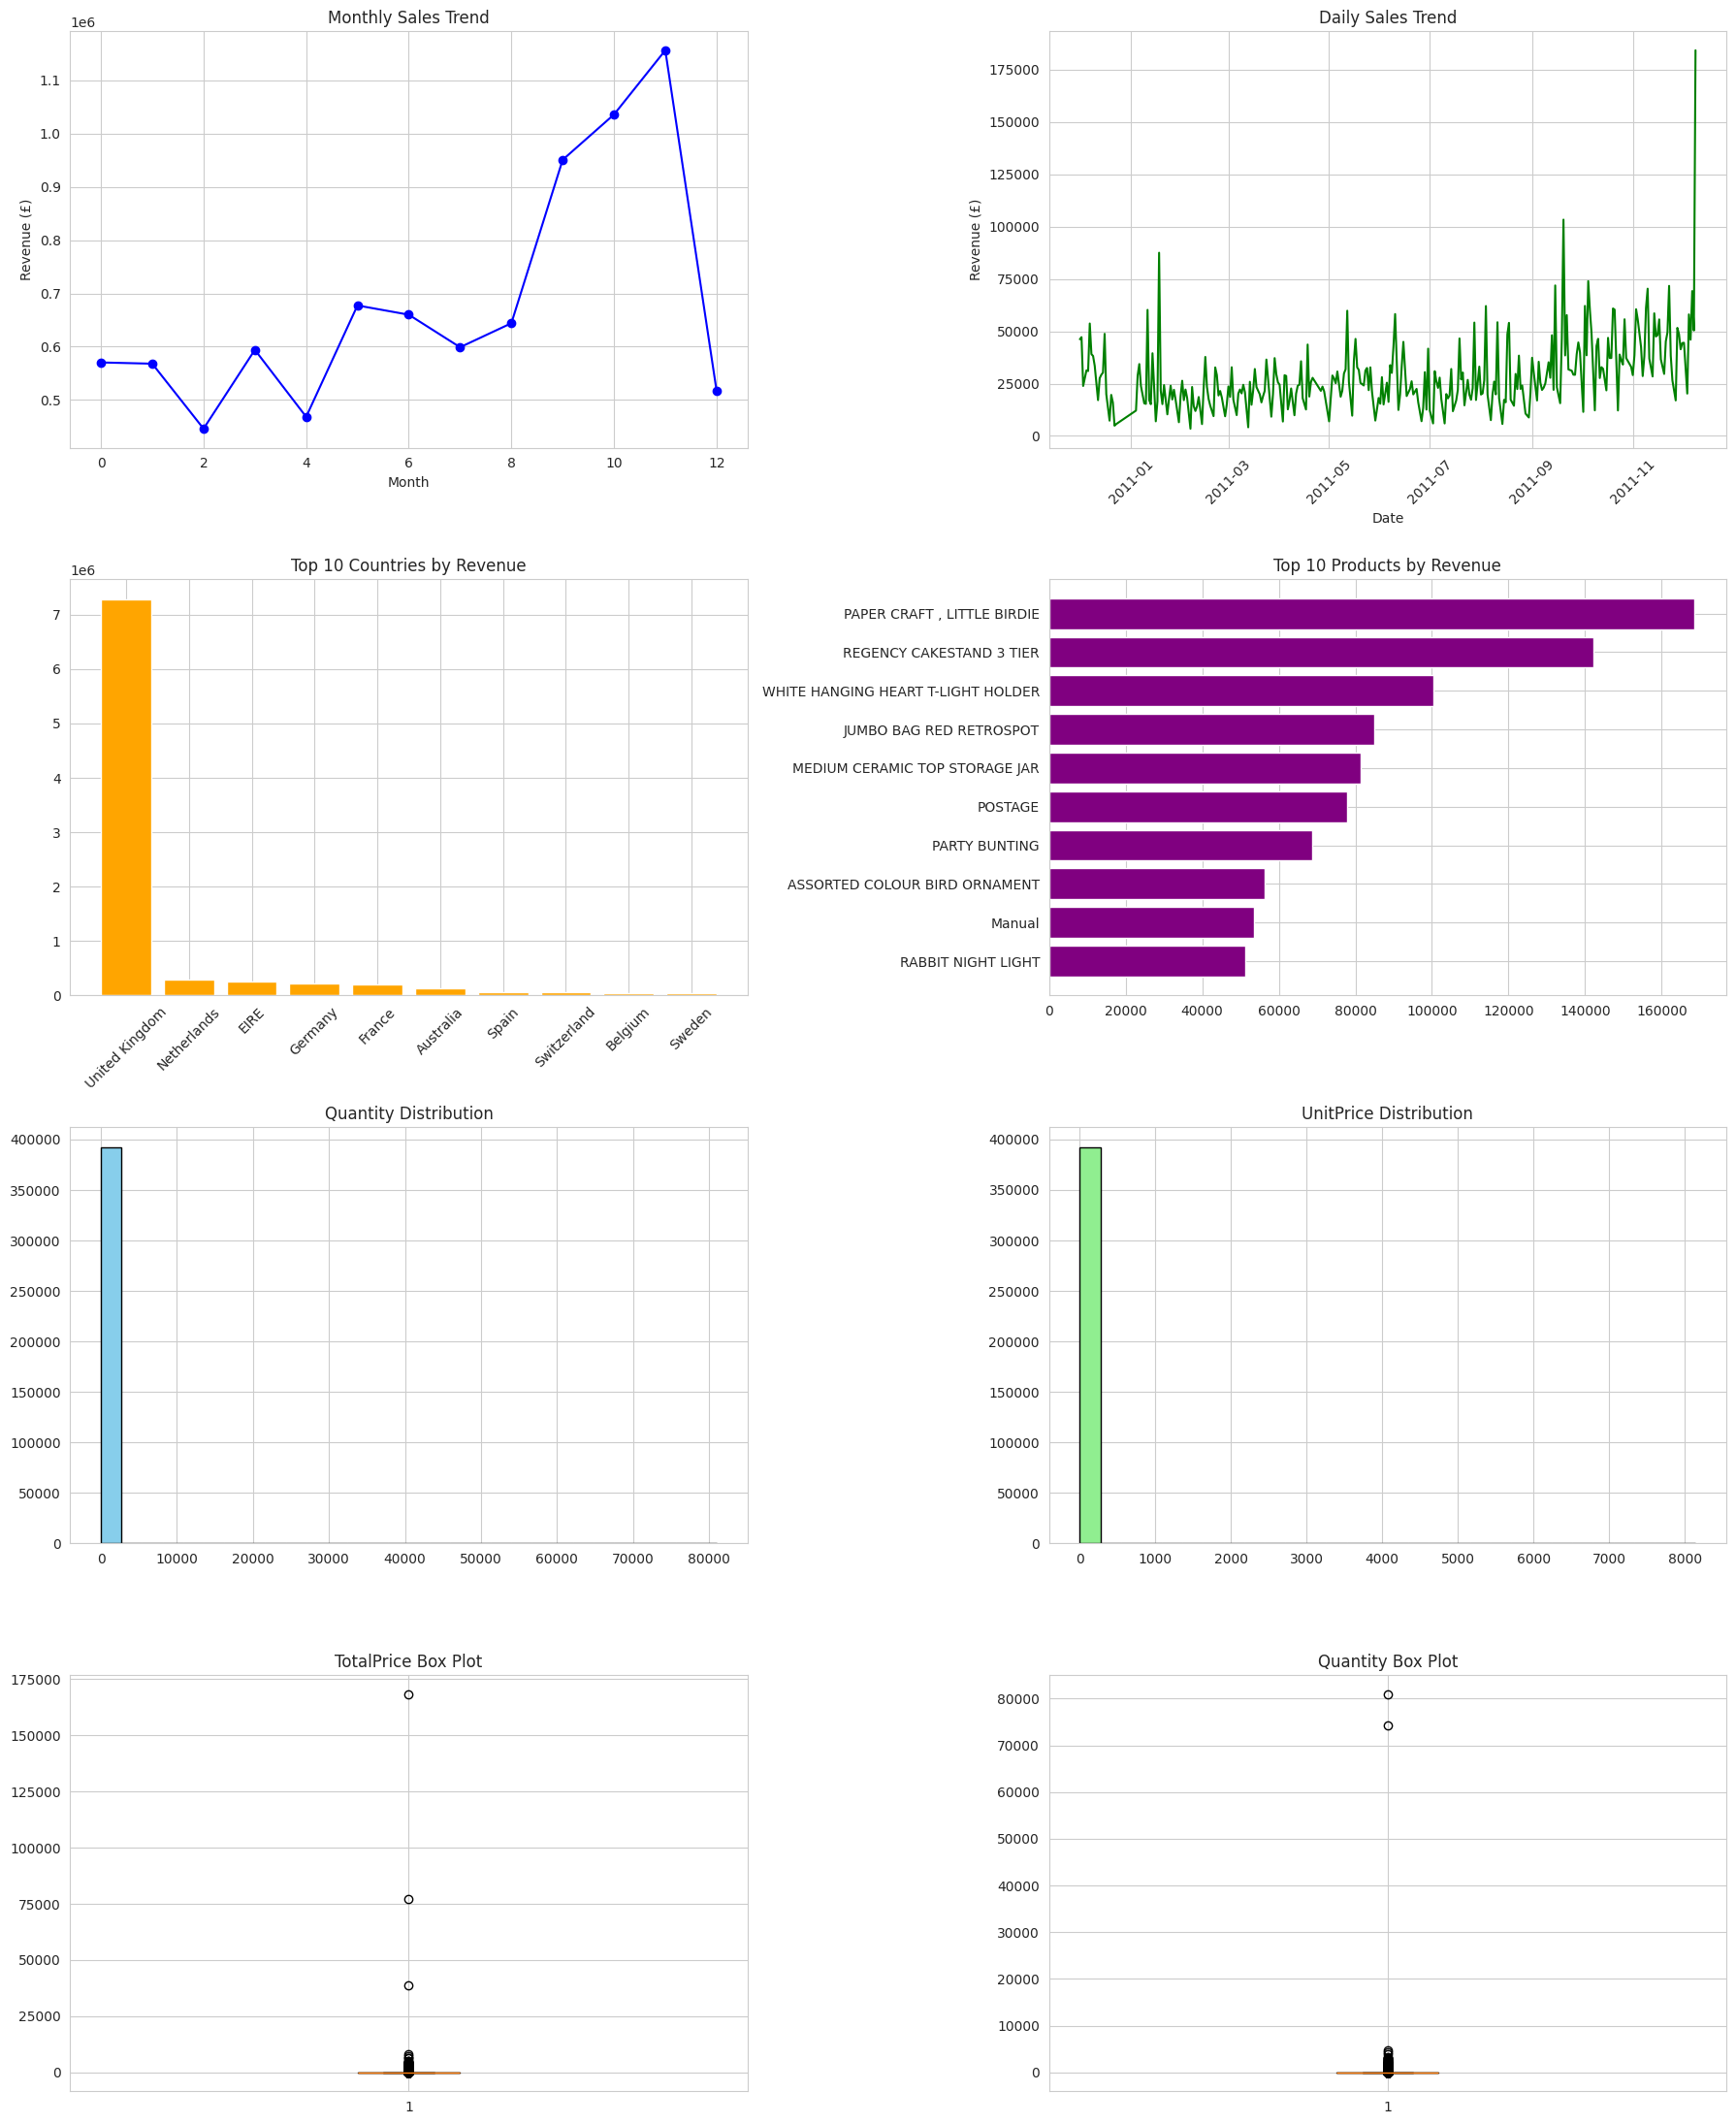

In [39]:
import matplotlib.pyplot as plt

# Create 8 plots
fig, axes = plt.subplots(4, 2, figsize=(18, 22))

# 1. Monthly Sales Trend
monthly_sales = df.groupby(
    ['Year', 'Month']
)['TotalPrice'].sum()

axes[0, 0].plot(
    range(len(monthly_sales)),
    monthly_sales.values,
    marker='o',
    color='blue'
)
axes[0, 0].set_title('Monthly Sales Trend')
axes[0, 0].set_xlabel('Month')
axes[0, 0].set_ylabel('Revenue (£)')

# 2. Daily Sales Trend
daily_sales = df.groupby(
    df['InvoiceDate'].dt.date
)['TotalPrice'].sum()

axes[0, 1].plot(
    daily_sales.index,
    daily_sales.values,
    color='green'
)
axes[0, 1].set_title('Daily Sales Trend')
axes[0, 1].set_xlabel('Date')
axes[0, 1].set_ylabel('Revenue (£)')
axes[0, 1].tick_params(axis='x', rotation=45)

# 3. Top 10 Countries
top_countries = df.groupby(
    'Country'
)['TotalPrice'].sum().nlargest(10)

axes[1, 0].bar(
    top_countries.index,
    top_countries.values,
    color='orange'
)
axes[1, 0].set_title('Top 10 Countries by Revenue')
axes[1, 0].tick_params(axis='x', rotation=45)

# 4. Top 10 Products
top_products = df.groupby(
    'Description'
)['TotalPrice'].sum().nlargest(10)

axes[1, 1].barh(
    top_products.index[::-1],
    top_products.values[::-1],
    color='purple'
)
axes[1, 1].set_title('Top 10 Products by Revenue')

# 5. Quantity Histogram
axes[2, 0].hist(
    df['Quantity'],
    bins=30,
    color='skyblue',
    edgecolor='black'
)
axes[2, 0].set_title('Quantity Distribution')

# 6. UnitPrice Histogram
axes[2, 1].hist(
    df['UnitPrice'],
    bins=30,
    color='lightgreen',
    edgecolor='black'
)
axes[2, 1].set_title('UnitPrice Distribution')

# 7. TotalPrice Box Plot
axes[3, 0].boxplot(df['TotalPrice'])
axes[3, 0].set_title('TotalPrice Box Plot')

# 8. Quantity Box Plot
axes[3, 1].boxplot(df['Quantity'])
axes[3, 1].set_title('Quantity Box Plot')

# Adjust layout
plt.tight_layout()
plt.show()

Seaborn:
● Count plot
● Violin plot
● Heatmap
● Pair plot

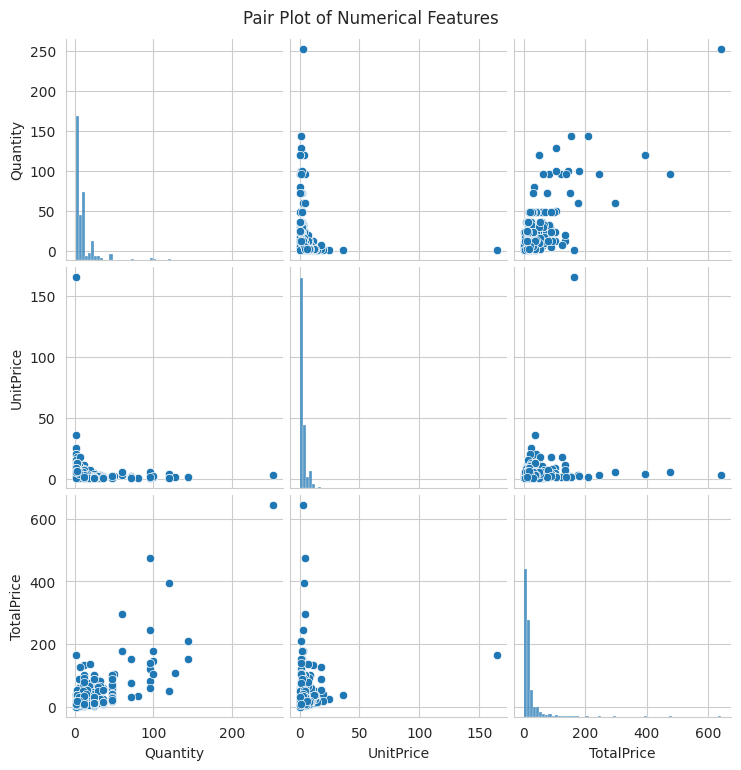

In [40]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.set_style('whitegrid')

# Create 2x2 subplot layout
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# 1. Count Plot
sns.countplot(
    data=df,
    x='Customer Segment',
    hue='Customer Segment',
    palette='Set2',
    legend=False,
    ax=axes[0, 0]
)

axes[0, 0].set_title('Customer Segment Count')
axes[0, 0].set_xlabel('Customer Segment')
axes[0, 0].set_ylabel('Count')

# 2. Violin Plot
sns.violinplot(
    data=df,
    x='Order Size',
    y='Quantity',
    hue='Order Size',
    palette='muted',
    legend=False,
    ax=axes[0, 1]
)

axes[0, 1].set_title('Quantity Distribution by Order Size')

# 3. Heatmap
corr = df[
    ['Quantity', 'UnitPrice', 'TotalPrice']
].corr()

sns.heatmap(
    corr,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    ax=axes[1, 0]
)

axes[1, 0].set_title('Correlation Heatmap')

# 4. Pair Plot
plt.close()

pair_data = df[
    ['Quantity', 'UnitPrice', 'TotalPrice']
].sample(
    n=min(1000, len(df)),
    random_state=42
)

sns.pairplot(
    pair_data,
    diag_kind='hist'
)

plt.suptitle('Pair Plot of Numerical Features', y=1.02)

plt.show()

# Display first three plots
fig.tight_layout()
plt.show()

Task 8 – Business Insights
● Identify:
○ Top country
○ Best sales month
○ Peak sales time
● Analyze:
○ Customer behavior
○ High-value customers
○ Top products

In [41]:
# 1. Top Country
country_sales = df.groupby('Country')['TotalPrice'].sum()

top_country = country_sales.idxmax()

print("TOP COUNTRY:", top_country)
print("Revenue:", country_sales.max())


# 2. Best Sales Month
monthly_sales = df.groupby(
    ['Year', 'Month']
)['TotalPrice'].sum()

best_month = monthly_sales.idxmax()

print("\nBEST SALES MONTH:", best_month)
print("Revenue:", monthly_sales.max())


# 3. Peak Sales Time
hourly_sales = df.groupby('Hour')['TotalPrice'].sum()

peak_hour = hourly_sales.idxmax()

print("\nPEAK SALES HOUR:", peak_hour)
print("Revenue:", hourly_sales.max())


# 4. Customer Behavior
customer_behavior = df.groupby('CustomerID').agg({
    'InvoiceNo': 'nunique',
    'Quantity': 'sum',
    'TotalPrice': 'sum'
}).reset_index()

customer_behavior.columns = [
    'CustomerID',
    'Total Orders',
    'Total Quantity',
    'Total Spending'
]

print("\nCUSTOMER BEHAVIOR:")
print(customer_behavior.head())


# 5. High-Value Customers
high_value_customers = customer_behavior.sort_values(
    by='Total Spending',
    ascending=False
).head(10)

print("\nTOP 10 HIGH-VALUE CUSTOMERS:")
print(high_value_customers)


# 6. Top Products
top_products = df.groupby(
    'Description'
)['TotalPrice'].sum().sort_values(
    ascending=False
).head(10)

print("\nTOP 10 PRODUCTS:")
print(top_products)

TOP COUNTRY: United Kingdom
Revenue: 7285024.644

BEST SALES MONTH: (np.int32(2011), np.int32(11))
Revenue: 1156205.61

PEAK SALES HOUR: 12
Revenue: 1373695.39

CUSTOMER BEHAVIOR:
   CustomerID  Total Orders  Total Quantity  Total Spending
0     12346.0             1           74215        77183.60
1     12347.0             7            2458         4310.00
2     12348.0             4            2341         1797.24
3     12349.0             1             631         1757.55
4     12350.0             1             197          334.40

TOP 10 HIGH-VALUE CUSTOMERS:
      CustomerID  Total Orders  Total Quantity  Total Spending
1689     14646.0            73          196915       280206.02
4201     18102.0            60           64124       259657.30
3728     17450.0            46           69973       194390.79
3008     16446.0             2           80997       168472.50
1879     14911.0           201           80240       143711.17
55       12415.0            21           77374      